# Portrait of Niche Cinema: How IMDb Rating Relates to Popularity

**Final Team Project — Data Scraping and Analysis with Python**

**Project:** Team project (2 participants)

**My contribution:** Data collection and cleaning,
statistical analysis, data visualization.

**Research question.** How do IMDb ratings relate to the number of votes across different genres?
Which genres are "for the masses" and which are "for connoisseurs"?
Do "niche" films share common traits — release year, runtime, genre?

**Pipeline in this notebook**

| Stage | What happens | Output |
|---|---|---|
| 0 | Setup: libraries, folders, data-version constants | — |
| 1 | Data collection: download two IMDb datasets with `requests`, describe their structure, join them by `tconst`; load the frozen research snapshot | `data/interim/imdb_raw_latest.csv`, `data/interim/imdb_raw_2026-10-16.csv` |
| 2 | Data cleaning; check that cleaning reproduces the frozen dataset; sensitivity to the data version | `data/clean/imdb_clean.csv` (= `imdb_clean_FROZEN_2026-10-16.csv`) |
| 3 | Exploratory data analysis, statistical tests and visualization | figures in `figures/` |
| 4 | Key findings, limitations, conclusions and recommendations | — |

**How to run.** Keep the notebook next to the `data/` folder from the submitted archive and run all cells
from top to bottom (*Kernel → Restart & Run All*). Python ≥ 3.9 with `requests`, `pandas`, `numpy`,
`matplotlib`, `scipy`. In Google Colab, upload the notebook and the whole `data/` folder to `/content/` first.
The download step needs internet access; without it the notebook prints a warning and continues with the
frozen snapshot, so the analysis always runs on exactly the same data.

# Stage 0. Setup

In [ ]:
# Install the libraries used in the project (already present in Anaconda and Colab)
%pip install -q requests pandas numpy matplotlib scipy

Note: you may need to restart the kernel to use updated packages.


In [ ]:
import json                                # read/write the source log in JSON
import hashlib                             # SHA-256 / MD5 fingerprints of files
from datetime import datetime, timezone    # access date of each source (UTC)
from pathlib import Path                   # OS-independent file paths

import numpy as np
import pandas as pd
import requests                            # HTTP requests to download files
import matplotlib.pyplot as plt
from scipy import stats                    # statistical tests

# Show all columns and use a wider console when printing tables
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

# --- Plot style: one style and one colour set for all figures ---------------
plt.rcParams.update({
    "figure.figsize": (10, 6), "figure.dpi": 100,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "axes.titleweight": "bold",
})
COLORS = {"niche": "#2a78d6", "mass": "#eb6834", "obscure": "#1baf7a", "all": "#9a9893"}

# --- Folders (all paths are relative, so the notebook runs on any machine) ---
DATA_DIR = Path("data")
RAW_DIR = DATA_DIR / "raw"                 # source logs + original IMDb files
RAW_IMDB = RAW_DIR / "imdb"                # original IMDb files, never modified
INTERIM = DATA_DIR / "interim"             # merged (not cleaned) tables
CLEAN = DATA_DIR / "clean"                 # cleaned tables
FIG_DIR = Path("figures")                  # charts used in the report
for p in (RAW_IMDB, INTERIM, CLEAN, FIG_DIR):
    p.mkdir(parents=True, exist_ok=True)

def save_fig(name: str) -> None:
    # Save the current figure for the written report
    plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

def md5(path: Path) -> str:
    # MD5 of a file: identical hash = byte-for-byte identical file
    h = hashlib.md5()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(1024 * 1024), b""):
            h.update(block)
    return h.hexdigest()

print("Folders ready:", [str(p) for p in (RAW_IMDB, INTERIM, CLEAN, FIG_DIR)])

Folders ready: ['data/raw/imdb', 'data/interim', 'data/clean', 'figures']


### Data versions used in the project

IMDb publishes only the **current** version of its datasets and updates them every day; older versions
cannot be downloaded again. To keep the analysis reproducible we work with **frozen snapshots** that are
submitted together with the notebook:

| Version | Files (in the archive) | What it was used for |
|---|---|---|
| **from 04.10** | `data/raw/sources_log_2026-10-04.json`, `data/interim/imdb_raw_2026-10-04.csv` | Project Progress Review (Stage 1). IMDb files downloaded on 04.10.2026 18:15 UTC; their size and SHA-256 are in the log. Used here only for the sensitivity check in Section 2.4 |
| **from 16.10** | `data/interim/imdb_raw_2026-10-16.csv`, `data/clean/imdb_clean_FROZEN_2026-10-16.csv`, `data/clean/DATASET_FINGERPRINT_2026-10-16.txt` | **Final project.** Stage 1 was re-run on 16.10.2026, the merged table was saved, cleaned (Stage 2) and frozen with a fingerprint. **All analysis uses this version** |
| latest | created when the notebook runs: `data/raw/sources_log_latest.json`, `data/interim/imdb_raw_latest.csv` | Shows that the collection code works today. Never overwrites the frozen files |

For the 16.10 download the source log with SHA-256 hashes of the `.tsv.gz` files was not preserved, so
that version is identified by the MD5 fingerprints of the merged and cleaned CSV files below.
Section 2.3 proves that the cleaning code applied to `imdb_raw_2026-10-16.csv` reproduces the frozen
dataset exactly.

In [ ]:
# --- Frozen snapshot of the final project (version from 16.10) -------------
RAW_1610 = INTERIM / "imdb_raw_2026-10-16.csv"
RAW_1610_MD5 = "ab73aa6fbc040f307f9d6a3f159e791d"           # merged table, not cleaned
FROZEN = CLEAN / "imdb_clean_FROZEN_2026-10-16.csv"
FINGERPRINT = CLEAN / "DATASET_FINGERPRINT_2026-10-16.txt"   # contains the MD5 of FROZEN

# --- Version from 04.10 (Project Progress Review) --------------------------
RAW_0410 = INTERIM / "imdb_raw_2026-10-04.csv"
RAW_0410_MD5 = "6691009eca442be17cb37b0bc52702d9"
SOURCES_LOG_0410 = RAW_DIR / "sources_log_2026-10-04.json"

# --- Files written by the current run (never the frozen ones) --------------
SOURCES_LOG_LATEST = RAW_DIR / "sources_log_latest.json"
RAW_LATEST = INTERIM / "imdb_raw_latest.csv"

for f in (RAW_1610, FROZEN, FINGERPRINT, RAW_0410, SOURCES_LOG_0410):
    status = "found" if f.exists() else "MISSING — copy it from the submitted archive"
    print(f"{str(f):50s} {status}")

data/interim/imdb_raw_2026-10-16.csv               found
data/clean/imdb_clean_FROZEN_2026-10-16.csv        found
data/clean/DATASET_FINGERPRINT_2026-10-16.txt      found
data/interim/imdb_raw_2026-10-04.csv               found
data/raw/sources_log_2026-10-04.json               found


# Stage 1. Data Collection

Two open IMDb datasets are downloaded from the official IMDb website with `requests`, their structure is
described, and they are joined by the key `tconst` into one table.

## 1.1 Source: IMDb — basic title information

**File:** `title.basics.tsv.gz`
**URL:** https://datasets.imdbws.com/title.basics.tsv.gz
**Documentation:** https://developer.imdb.com/non-commercial-datasets/
**Access dates:** 04.10.2026 (Progress Review version), 16.10.2026 (final-project version); the current run
writes its own access time (UTC) to `data/raw/sources_log_latest.json`.
**Format:** TSV (tab-separated values), gzip-compressed, about 230 MB, about 12.9 million rows; empty values are written as `\N`.

**Fields** (according to the official IMDb documentation):

| Field | Type / unit | Description |
|---|---|---|
| `tconst` | string | alphanumeric unique identifier of the title |
| `titleType` | string | type/format of the title (movie, short, tvSeries, tvEpisode, video, etc.) |
| `primaryTitle` | string | the more popular title / the title used by the filmmakers on promotional materials |
| `originalTitle` | string | original title, in the original language |
| `isAdult` | boolean | 0: non-adult title; 1: adult title |
| `startYear` | year (YYYY) | release year of the title (for TV series — the start year) |
| `endYear` | year (YYYY) | TV series end year; `\N` for all other title types |
| `runtimeMinutes` | integer, minutes | primary runtime of the title |
| `genres` | string array | up to three genres associated with the title |

**Time range:** the full file covers titles from 1874 to announced releases far in the future (printed in 1.4);
our research population covers feature films released in **1980–2025**.

**License:** non-commercial use only. **Attribution:** Information courtesy of IMDb (https://www.imdb.com). Used with permission.

**Relation to other sources:** key `tconst`, shared with `title.ratings.tsv.gz`.

## 1.2 Source: IMDb — ratings

**File:** `title.ratings.tsv.gz`
**URL:** https://datasets.imdbws.com/title.ratings.tsv.gz
**Documentation:** https://developer.imdb.com/non-commercial-datasets/
**Access dates:** same as `title.basics.tsv.gz` (both files are always downloaded together).
**Format:** TSV, gzip-compressed, about 9 MB, about 1.7 million rows.

| Field | Type / unit | Description |
|---|---|---|
| `tconst` | string | alphanumeric unique identifier of the title |
| `averageRating` | float, scale 1–10 | weighted average of all individual user ratings |
| `numVotes` | integer, votes | number of votes the title has received |

**Time range:** matches `title.basics.tsv.gz` — only titles that have received at least one rating are listed.
**License / attribution:** as above. **Relation to other sources:** key `tconst`, shared with `title.basics.tsv.gz`.

## 1.3 Download the datasets

Files are downloaded as a stream from the official IMDb website.

- If the server answers with an error code (4xx or 5xx), `r.raise_for_status()` **raises a `requests.HTTPError`
  exception**, which stops the download of that file.
- The file is first written to a temporary `.part` file and renamed only after a successful download, so an
  incomplete file never appears in `data/raw/imdb/`.
- If a file already exists in `data/raw/imdb/`, it is not downloaded again.
- If there is no internet connection (or IMDb is unavailable), the exception is caught, a warning is printed and
  the notebook continues: the analysis uses the frozen snapshot, so it does not depend on this step.

For every file the following is written to `data/raw/sources_log_latest.json` (the log of the 04.10 version is never overwritten):
`url`; `accessed_at_utc` — the moment of download; `server_last_modified` — the date when IMDb last updated the
file (HTTP header `Last-Modified`); `size_bytes` and `sha256` — two files with the same SHA-256 are byte-for-byte identical.

In [ ]:
DOWNLOAD_LATEST_IMDB = True   # False = skip the download and work only with the frozen snapshots

IMDB_BASE = "https://datasets.imdbws.com/"                    # IMDb address to download data from
IMDB_FILES = ["title.basics.tsv.gz", "title.ratings.tsv.gz"]  # files to download
CHUNK_SIZE = 1024 * 1024                                      # 1 MB

sources_log = (json.loads(SOURCES_LOG_LATEST.read_text(encoding="utf-8"))
               if SOURCES_LOG_LATEST.exists() else {})

def download(url: str, dest: Path, chunk: int = CHUNK_SIZE):
    # Downloads a file as a stream; returns the server's Last-Modified header (or None)
    with requests.get(url, stream=True, timeout=(10, 300)) as r:
        # On a 4xx/5xx response raise_for_status() raises requests.HTTPError,
        # so an error page is never saved as a data file
        r.raise_for_status()
        tmp = dest.with_suffix(dest.suffix + ".part")   # temporary file
        with open(tmp, "wb") as f:
            for part in r.iter_content(chunk_size=chunk):
                f.write(part)
        tmp.replace(dest)                               # rename only after success
        return r.headers.get("Last-Modified")

def sha256(path: Path, chunk: int = CHUNK_SIZE) -> str:
    # SHA-256 hash of a file: identical hash = byte-for-byte identical file version
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(chunk), b""):
            h.update(block)
    return h.hexdigest()

def save_log() -> None:
    SOURCES_LOG_LATEST.write_text(json.dumps(sources_log, ensure_ascii=False, indent=2), encoding="utf-8")

LATEST_OK = False
if DOWNLOAD_LATEST_IMDB:
    try:
        for fname in IMDB_FILES:
            dest, url, key = RAW_IMDB / fname, IMDB_BASE + fname, f"imdb/{fname}"
            if dest.exists():
                print(f"{fname}: already downloaded ({dest.stat().st_size / 1e6:.1f} MB)")
                if key not in sources_log:   # downloaded earlier but not logged: use file time
                    mtime = datetime.fromtimestamp(dest.stat().st_mtime, tz=timezone.utc)
                    sources_log[key] = {"url": url, "accessed_at_utc": mtime.strftime("%Y-%m-%d %H:%M"),
                                        "note": "date = file modification time", "server_last_modified": None}
            else:
                print(f"{fname}: downloading...", flush=True)
                last_modified = download(url, dest)
                print(f"{fname}: done ({dest.stat().st_size / 1e6:.1f} MB)")
                sources_log[key] = {"url": url,
                                    "accessed_at_utc": datetime.now(timezone.utc).strftime("%Y-%m-%d %H:%M"),
                                    "note": "IMDb Non-Commercial Datasets",
                                    "server_last_modified": last_modified}
            sources_log[key]["size_bytes"] = dest.stat().st_size
            sources_log[key]["sha256"] = sha256(dest)
            save_log()
        LATEST_OK = True
    except (requests.RequestException, OSError) as err:
        print("WARNING: the IMDb download failed, so the latest version is skipped.")
        print("         The analysis uses the frozen snapshot from 16.10. Details:", repr(err)[:200])

if LATEST_OK:
    print("\nSource log of this run (data/raw/sources_log_latest.json):")
    print(json.dumps(sources_log, ensure_ascii=False, indent=2))

print("\nSource log of the Progress Review version (data/raw/sources_log_2026-10-04.json):")
print(SOURCES_LOG_0410.read_text(encoding="utf-8"))

title.basics.tsv.gz: downloading...


         The analysis uses the frozen snapshot from 16.10. Details: ProxyError(MaxRetryError("HTTPSConnectionPool(host='datasets.imdbws.com', port=443): Max retries exceeded with url: /title.basics.tsv.gz (Caused by ProxyError('Unable to connect to proxy', OSError('Tu

Source log of the Progress Review version (data/raw/sources_log_2026-10-04.json):
{
  "imdb/title.basics.tsv.gz": {
    "url": "https://datasets.imdbws.com/title.basics.tsv.gz",
    "accessed_at_utc": "2026-10-04 18:15",
    "note": "IMDb Non-Commercial Datasets",
    "server_last_modified": "Sun, 04 Oct 2026 00:37:22 GMT",
    "size_bytes": 228034157,
    "sha256": "1f6dc1c7b27b648228d11f6ff9d78c6b8f80d5de4fb1f89efbf56d35a7050ae0"
  },
  "imdb/title.ratings.tsv.gz": {
    "url": "https://datasets.imdbws.com/title.ratings.tsv.gz",
    "accessed_at_utc": "2026-10-04 18:15",
    "note": "IMDb Non-Commercial Datasets",
    "server_last_modified": "Sun, 04 Oct 2026 00:38:25 GMT",
    "size_bytes": 8673057,
    "sha256": "5fd

## 1.4 Population selection and structure of `title.basics.tsv.gz`

The full file contains every IMDb title type. We read the **whole file** in chunks of 1 million rows and keep
all observations that fit the research question. This is **selection of the research population, not cleaning**:
values inside the selected rows are not changed, and no random sample is drawn.

- `TITLE_TYPES = ["movie"]` — feature films only (no series, episodes, shorts);
- `YEAR_FROM = 1980`, `YEAR_TO = 2025` — 2026 is excluded because recent releases have not collected votes yet.

Reading parameters: `sep="\t"`; `na_values="\\N"` (IMDb writes empty values as `\N`); `keep_default_na=False`
(**only** `\N` is missing — otherwise real titles such as "NA", "Null" or "None" would be lost); `dtype=str`
(type conversion belongs to cleaning); `quoting=3` (titles with a single `"` would otherwise merge rows).

In [ ]:
TITLE_TYPES = ["movie"]   # feature films only
YEAR_FROM = 1980          # first release year; None = no lower bound
YEAR_TO = 2025            # last release year; None = no upper bound
READ_CHUNK = 1_000_000    # rows per chunk when reading title.basics (memory-safe)

if LATEST_OK:
    reader = pd.read_csv(RAW_IMDB / "title.basics.tsv.gz", sep="\t", compression="gzip",
                         na_values="\\N", keep_default_na=False, dtype=str, quoting=3,
                         chunksize=READ_CHUNK)
    parts, total_rows = [], 0
    type_counts = pd.Series(dtype="int64")
    year_min, year_max = None, None
    for chunk in reader:
        # statistics of the whole file, before any selection
        total_rows += len(chunk)
        type_counts = type_counts.add(chunk["titleType"].value_counts(), fill_value=0)
        year = pd.to_numeric(chunk["startYear"], errors="coerce")   # numeric copy only for filtering
        if year.notna().any():
            year_min = year.min() if year_min is None else min(year_min, year.min())
            year_max = year.max() if year_max is None else max(year_max, year.max())
        # selection: right title type and release year inside [YEAR_FROM, YEAR_TO]
        mask = chunk["titleType"].isin(TITLE_TYPES)
        if YEAR_FROM is not None:
            mask &= year >= YEAR_FROM
        if YEAR_TO is not None:
            mask &= year <= YEAR_TO
        parts.append(chunk[mask])
    basics = pd.concat(parts, ignore_index=True)
    del parts

    print("title.basics.tsv.gz — whole file")
    print(f"Total rows: {total_rows:,}; release years: {int(year_min)}–{int(year_max)}")
    print("\nTitle types (whole file):")
    print(type_counts.astype(int).sort_values(ascending=False))
    print(f"\nSelected: types={TITLE_TYPES}, years={YEAR_FROM}–{YEAR_TO}; shape: {basics.shape}")
    print(basics.head())
    basics.info()
    print("\nMissing values per column:")
    print(basics.isna().sum())
else:
    print("Latest IMDb files are not available in this run — see the frozen snapshot in 1.6.")

Latest IMDb files are not available in this run — see the frozen snapshot in 1.6.


## 1.5 Structure of `title.ratings.tsv.gz` and joining the sources

**Key:** `tconst`, present in both files; relationship **one-to-one** (each title has at most one rating row).
`validate="one_to_one"` makes pandas raise an error if a key is duplicated in either file.
We use an **inner join**: all selected films that have a rating record are kept, because the research question
requires the rating and the vote count. Films without a rating are counted first.
The result is saved in **UTF-8** (set explicitly: titles contain Cyrillic, CJK and other non-ASCII characters,
and the file must open the same way on Windows, Linux and macOS).

In [ ]:
if LATEST_OK:
    ratings = pd.read_csv(RAW_IMDB / "title.ratings.tsv.gz", sep="\t", compression="gzip", na_values="\\N")
    print("title.ratings.tsv.gz — shape:", ratings.shape)
    print(ratings.head())
    ratings.info()

    has_rating = basics["tconst"].isin(ratings["tconst"])
    print("\nSelected films with / without a rating:")
    print(has_rating.value_counts().rename({True: "with rating", False: "no rating"}))

    imdb_latest = pd.merge(basics, ratings, on="tconst", how="inner",
                           validate="one_to_one").reset_index(drop=True)
    print(f"\nFilms after the join (latest version): {len(imdb_latest):,}")
    imdb_latest.to_csv(RAW_LATEST, index=False, encoding="utf-8")
    print(f"Saved: {RAW_LATEST} — the frozen snapshots are not touched")
    del basics, ratings
else:
    print("Latest IMDb files are not available in this run — nothing to join.")

Latest IMDb files are not available in this run — nothing to join.


## 1.6 The research snapshot from 16.10 — unified view of the collected data

The analysis uses the merged table produced by exactly the code above on **16.10.2026**.
Its MD5 fingerprint is checked first, so we know the file is the original one.

In [ ]:
assert md5(RAW_1610) == RAW_1610_MD5, (
    "imdb_raw_2026-10-16.csv differs from the original snapshot — copy it again from the archive")
print("MD5 check passed:", RAW_1610.name)

raw = pd.read_csv(RAW_1610, encoding="utf-8", keep_default_na=False, na_values=[""])  # only empty cells are missing
print("Shape:", raw.shape)
print("\nColumns:", list(raw.columns))
print("\nFirst 5 rows:")
print(raw.head())
print("\nTypes:")
print(raw.dtypes)

years = raw["startYear"]
print(f"\nRelease years: {years.min()}–{years.max()}")
print("\nFilms per decade:")
print((years // 10 * 10).value_counts().sort_index())

print("\nMissing values (count and %):")
print(pd.DataFrame({"missing": raw.isna().sum(),
                    "missing_%": (raw.isna().mean() * 100).round(2)}))

MD5 check passed: imdb_raw_2026-10-16.csv


Shape: (263551, 11)

Columns: ['tconst', 'titleType', 'primaryTitle', 'originalTitle', 'isAdult', 'startYear', 'endYear', 'runtimeMinutes', 'genres', 'averageRating', 'numVotes']

First 5 rows:
      tconst titleType                 primaryTitle                originalTitle  isAdult  startYear  endYear  runtimeMinutes                  genres  averageRating  numVotes
0  tt0015724     movie                Dama de noche                Dama de noche        0       1993      NaN           102.0   Drama,Mystery,Romance            6.2        35
1  tt0035423     movie               Kate & Leopold               Kate & Leopold        0       2001      NaN           118.0  Comedy,Fantasy,Romance            6.4     94866
2  tt0036606     movie  Another Time, Another Place  Another Time, Another Place        0       1983      NaN           118.0               Drama,War            6.4       388
3  tt0038086     movie    Shiva und die Galgenblume    Shiva und die Galgenblume        0       1993      

**What we see.** The unified table has one row per film with 11 columns: 9 from `title.basics` and 2 from
`title.ratings`, joined by `tconst`. It contains 263,551 feature films released in 1980–2025. Most films are
recent: the 2010s alone contribute more than a third. The data still needs cleaning: `endYear` is
100% empty, `titleType` is constant, `genres` (2.7%) and `runtimeMinutes` (8.7%) have gaps, and adult titles are mixed in.

# Stage 2. Data Cleaning

## 2.1 Cleaning rules

**Input:** `data/interim/imdb_raw_2026-10-16.csv`. **Output:** `data/clean/imdb_clean.csv`, one row per film.

| Problem | Decision | Why |
|---|---|---|
| `endYear` is 100% empty, `titleType` is always `movie` | drop the columns | no information |
| Strings like `NA`, `Null`, `None` read as missing | read with `keep_default_na=False, na_values=[""]` | they can be real titles; only empty cells are gaps |
| Missing title | keep the row | titles are not used in the analysis |
| Missing `genres` (~2.7%) | drop the row; first compare these films with the rest | genre is the main grouping variable; the comparison shows what we cut |
| Adult films (`isAdult = 1`) | exclude | separate market with its own voting patterns; IMDb hides them from its main charts |
| `runtimeMinutes` from 1 to 51,420 min | values < 40 or > 600 min → `NaN`, the film stays | < 40 min is not a feature film (AMPAS/BFI definition); > 600 min are art installations such as *Logistics* (51,420 min). Rating and votes of these films are valid |
| Duplicates by `tconst` | check, expect 0 | `tconst` is the primary key |
| Data types | `startYear`, `numVotes` → int, `averageRating` → float, `runtimeMinutes` → nullable `Int64` | correct types for analysis |

Films with few votes are **not** removed here: the vote threshold is an analysis decision (Stage 3).
The cleaning steps are written as one function, so exactly the same rules can be applied to another data
version in Section 2.4.

In [ ]:
def clean_imdb(df: pd.DataFrame, verbose: bool = True) -> pd.DataFrame:
    # Cleans the merged IMDb table (rules from the table above)
    say = print if verbose else (lambda *a, **k: None)
    df = df.copy()
    say(f"Loaded: {df.shape[0]:,} rows, {df.shape[1]} columns")

    # 1. Drop columns that carry no information
    df = df.drop(columns=["endYear", "titleType"])

    # 2. Missing titles: kept, only reported
    miss_title = df["primaryTitle"].isna() | df["originalTitle"].isna()
    say(f"Rows with a missing title (kept): {miss_title.sum()}")

    # 3. Missing genres: compare with the rest, then drop
    no_genre = df["genres"].isna()
    if verbose:
        print("\nFilms with vs without genre:")
        print(df.groupby(no_genre.map({True: "no genre", False: "has genre"}))
                .agg(films=("tconst", "size"),
                     median_votes=("numVotes", "median"),
                     median_rating=("averageRating", "median")))
    df = df[~no_genre].reset_index(drop=True)
    say(f"Dropped {no_genre.sum():,} rows with missing genres")

    # 4. Adult films: drop, then drop the constant column
    adult = df["isAdult"].astype(int).astype(bool)
    df = df[~adult].drop(columns=["isAdult"]).reset_index(drop=True)
    say(f"Dropped {adult.sum():,} adult films -> {len(df):,} rows")

    # 5. Duplicates by the primary key
    say(f"Duplicates by tconst: {df.duplicated(subset=['tconst']).sum()}")

    # 6. Data types
    df["startYear"] = df["startYear"].astype("int64")
    df["numVotes"] = df["numVotes"].astype("int64")
    df["averageRating"] = df["averageRating"].astype("float64")
    df["runtimeMinutes"] = df["runtimeMinutes"].astype("Int64")

    # 7. Implausible runtimes -> NaN (the film itself is kept)
    bad_rt = (df["runtimeMinutes"] < 40) | (df["runtimeMinutes"] > 600)
    if verbose:
        print(f"\nRuntime anomalies: < 40 min: {(df['runtimeMinutes'] < 40).sum()}, "
              f"> 600 min: {(df['runtimeMinutes'] > 600).sum()}")
        print("Examples (longest):")
        print(df.loc[bad_rt, ["primaryTitle", "startYear", "runtimeMinutes", "numVotes"]]
                .sort_values("runtimeMinutes", ascending=False).head(8).to_string(index=False))
    df.loc[bad_rt, "runtimeMinutes"] = pd.NA
    say(f"Runtime set to NaN: {int(bad_rt.sum())} films")
    return df

df_clean = clean_imdb(raw)

Loaded: 263,551 rows, 11 columns
Rows with a missing title (kept): 0

Films with vs without genre:


            films  median_votes  median_rating
genres                                        
has genre  256340          74.0            6.3
no genre     7211          16.0            6.2
Dropped 7,211 rows with missing genres
Dropped 2,756 adult films -> 253,584 rows
Duplicates by tconst: 0

Runtime anomalies: < 40 min: 62, > 600 min: 33
Examples (longest):
                   primaryTitle  startYear  runtimeMinutes  numVotes
                      Logistics       2012           51420       408
                       Ambiancé       2020           43200       146
Carnets Filmés (Liste Complète)       2019           28643        17
           Modern Times Forever       2011           14400       105
                   Beijing 2003       2004            9000        38
                    Matrjoschka       2006            5700        49
                     London EC1       2015            5460        15
          The Cure for Insomnia       1987            5220       448
Runtime set to NaN

## 2.2 Sanity checks and saving the cleaned table

In [ ]:
# --- Sanity checks ------------------------------------------------------------
print("Final dtypes:")
print(df_clean.dtypes)
print(f"\nstartYear: {df_clean['startYear'].min()}–{df_clean['startYear'].max()}")
print(f"runtimeMinutes: {df_clean['runtimeMinutes'].min()}–{df_clean['runtimeMinutes'].max()} "
      f"(NaN: {df_clean['runtimeMinutes'].isna().sum():,})")
print(f"averageRating: {df_clean['averageRating'].min()}–{df_clean['averageRating'].max()}")
print(f"numVotes: {df_clean['numVotes'].min():,}–{df_clean['numVotes'].max():,}")
print(f"Missing values left:\n{df_clean.isna().sum()}")

OUT_CLEAN = CLEAN / "imdb_clean.csv"
df_clean.to_csv(OUT_CLEAN, index=False, encoding="utf-8")
print(f"\nSaved: {OUT_CLEAN}  shape: {df_clean.shape}")

Final dtypes:
tconst                str
primaryTitle          str
originalTitle         str
startYear           int64
runtimeMinutes      Int64
genres                str
averageRating     float64
numVotes            int64
dtype: object

startYear: 1980–2025
runtimeMinutes: 40–600 (NaN: 19,573)
averageRating: 1.0–10.0
numVotes: 5–3,245,753
Missing values left:
tconst                0
primaryTitle          0
originalTitle         0
startYear             0
runtimeMinutes    19573
genres                0
averageRating         0
numVotes              0
dtype: int64



Saved: data/clean/imdb_clean.csv  shape: (253584, 8)


**Result of cleaning.** 263,551 → 253,584 films: 7,211 films without a genre and 2,756 adult films were removed.
Films without a genre are clearly less visible (median 16 votes vs 74). Dropping them removes some of the most
obscure titles, which is noted in the limitations. 95 implausible runtimes were set to `NaN`; the films stay
in the rating and vote analysis. No duplicates were found.

## 2.3 Freezing the cleaned dataset and verifying it

On 16.10 the cleaned table was **frozen**: copied to `imdb_clean_FROZEN_2026-10-16.csv` with a fingerprint
(`DATASET_FINGERPRINT_2026-10-16.txt`: row count, key statistics and MD5).
The cell below does two checks:

1. the MD5 of the frozen file equals the MD5 written in the fingerprint, so the file is unchanged;
2. the table just produced by `clean_imdb()` is **identical in content** to the frozen one.
   Content is compared, not MD5: the frozen file was written on Windows (line ending `\r\n`), and on macOS or Linux the same
   data is written with `\n`, which changes the bytes but not the data.

If the frozen file did not exist, the cell would create it together with its fingerprint (the original freezing step).

In [ ]:
def read_fingerprint(path: Path) -> dict:
    # Parses 'key: value' lines of the fingerprint file
    fp = {}
    for line in path.read_text(encoding="utf-8").splitlines():
        if ":" in line:
            k, v = line.split(":", 1)
            fp[k.strip()] = v.strip()
    return fp

if not FROZEN.exists():
    # Original freezing step (runs only if there is no frozen file yet)
    df_clean.to_csv(FROZEN, index=False, encoding="utf-8")
    lines = ["DATASET FINGERPRINT", "=" * 40]
    for k, v in {"frozen_date": datetime.now().date().isoformat(), "frozen_file": str(FROZEN),
                 "rows": len(df_clean), "md5": md5(FROZEN)}.items():
        lines.append(f"{k:>16}: {v}")
    FINGERPRINT.write_text("\n".join(lines), encoding="utf-8")
    print("Frozen file and fingerprint created.")

fp = read_fingerprint(FINGERPRINT)
print("Fingerprint:", {k: fp[k] for k in ("frozen_date", "rows", "md5")})

# Check 1: the frozen file is byte-for-byte the original one
assert md5(FROZEN) == fp["md5"], "Frozen file was modified — copy it again from the archive"
print("Check 1 passed: MD5 of the frozen file matches the fingerprint")

# Check 2: our cleaning reproduces the frozen data exactly (read both back from CSV the same way)
opts = dict(encoding="utf-8", keep_default_na=False, na_values=[""])
frozen_df = pd.read_csv(FROZEN, **opts)
rebuilt_df = pd.read_csv(OUT_CLEAN, **opts)
pd.testing.assert_frame_equal(rebuilt_df, frozen_df, check_dtype=False)
assert len(frozen_df) == int(fp["rows"])
print(f"Check 2 passed: clean_imdb(imdb_raw_2026-10-16.csv) == frozen dataset ({len(frozen_df):,} rows)")

Fingerprint: {'frozen_date': '2026-10-16', 'rows': '253584', 'md5': '2242bb3eeca1dc65f9c76f7282eba180'}
Check 1 passed: MD5 of the frozen file matches the fingerprint


Check 2 passed: clean_imdb(imdb_raw_2026-10-16.csv) == frozen dataset (253,584 rows)


## 2.4 Sensitivity check: does the data version matter?

IMDb changes slightly every day (new votes, corrected genres, ratings that appear or disappear). We apply the
**same** cleaning function to the Progress Review version from 04.10 and compare it with the version from 16.10
(and with the latest download, if it is available in this run). If the key quantities barely move, the conclusions do not depend on the download date.

In [ ]:
def key_numbers(d: pd.DataFrame) -> dict:
    vt = d["numVotes"].quantile(0.90)
    rt = d["averageRating"].quantile(0.90)
    niche_n = ((d["numVotes"] >= 100) & (d["numVotes"] <= vt) & (d["averageRating"] >= rt)).sum()
    return {"films": len(d), "median votes": d["numVotes"].median(),
            "mean rating": round(d["averageRating"].mean(), 3),
            "90th pct of votes": vt, "90th pct of rating": rt,
            "niche high-rated": int(niche_n), "mass audience": int((d["numVotes"] > vt).sum())}

versions = {"from 16.10 (analysis)": frozen_df}
if RAW_0410.exists():
    assert md5(RAW_0410) == RAW_0410_MD5, "imdb_raw_2026-10-04.csv was modified"
    raw_0410 = pd.read_csv(RAW_0410, encoding="utf-8", keep_default_na=False, na_values=[""])
    versions["from 04.10 (Progress Review)"] = clean_imdb(raw_0410, verbose=False)
if LATEST_OK and RAW_LATEST.exists():
    raw_latest = pd.read_csv(RAW_LATEST, encoding="utf-8", keep_default_na=False, na_values=[""])
    versions["latest (this run)"] = clean_imdb(raw_latest, verbose=False)

print("Key numbers by data version:")
display(pd.DataFrame([key_numbers(d) for d in versions.values()], index=list(versions)))

if "from 04.10 (Progress Review)" in versions:
    a, b = versions["from 04.10 (Progress Review)"], frozen_df
    j = a.merge(b, on="tconst", suffixes=("_0410", "_1610"))
    print(f"Films only in 04.10: {len(set(a.tconst) - set(b.tconst))}, "
          f"only in 16.10: {len(set(b.tconst) - set(a.tconst))}, common: {len(j):,}")
    dv = j["numVotes_1610"] - j["numVotes_0410"]
    print(f"numVotes changed for {(dv != 0).mean() * 100:.1f}% of common films "
          f"(median change {dv.median():.0f}, mean {dv.mean():.2f} votes)")
    dr = (j["averageRating_1610"] - j["averageRating_0410"]).round(1)
    print(f"averageRating changed for {(dr != 0).mean() * 100:.2f}% of common films")

Key numbers by data version:


,films,median votes,mean rating,90th pct of votes,90th pct of rating,niche high-rated,mass audience
from 16.10 (analysis),253584,75.0,6.186,2305.0,8.0,2507,25356
from 04.10 (Progress Review),253614,75.0,6.185,2306.0,8.0,2503,25356


Films only in 04.10: 34, only in 16.10: 4, common: 253,580
numVotes changed for 12.9% of common films (median change 0, mean -1.18 votes)
averageRating changed for 0.61% of common films


**Conclusion.** Between 04.10 and 16.10 a few dozen films with 5–20 votes lost or gained their IMDb rating,
vote counts moved by about one vote on average, and the thresholds used in the analysis stayed practically the
same (90th percentile of votes 2,306 vs 2,305; rating 8.0 in both). **The results below do not depend on which
version is used**, and the frozen version from 16.10 makes every number in this notebook exactly reproducible.

# Stage 3. Exploratory Data Analysis

All calculations use the frozen dataset from 16.10 verified in Section 2.3.

In [ ]:
df = frozen_df.copy()
df["runtimeMinutes"] = df["runtimeMinutes"].astype("Int64")
print("Shape:", df.shape)
print(df.dtypes)
print("\nMissing values:\n", df.isna().sum(), sep="")

Shape: (253584, 8)
tconst                str
primaryTitle          str
originalTitle         str
startYear           int64
runtimeMinutes      Int64
genres                str
averageRating     float64
numVotes            int64
dtype: object

Missing values:
tconst                0
primaryTitle          0
originalTitle         0
startYear             0
runtimeMinutes    19573
genres                0
averageRating         0
numVotes              0
dtype: int64


## 3.1 Descriptive statistics

Summary statistics for the four numeric columns. Percentiles show the shape of the distributions, which
matters for the strongly skewed `numVotes`.

In [ ]:
num_cols = ["startYear", "runtimeMinutes", "averageRating", "numVotes"]
display(df[num_cols].astype("float64")
          .describe(percentiles=[.10, .25, .50, .75, .90, .95, .99]).round(2))

print("Skewness and kurtosis:")
for col in num_cols:
    s = df[col].astype("float64")
    print(f"{col:>15}: skew = {s.skew():>7.2f}, kurtosis = {s.kurtosis():>8.2f}")

,startYear,runtimeMinutes,averageRating,numVotes
count,253584.00,234011.00,253584.00,253584.00
mean,2010.27,94.97,6.19,4654.40
std,11.87,24.43,1.45,43458.72
min,1980.00,40.00,1.00,5.00
10%,1991.00,69.00,4.20,12.00
25%,2004.00,82.00,5.30,22.00
50%,2013.00,92.00,6.30,75.00
75%,2020.00,105.00,7.20,397.00
90%,2023.00,124.00,8.00,2305.00
95%,2024.00,139.00,8.40,7927.00


Skewness and kurtosis:
      startYear: skew =   -0.87, kurtosis =    -0.18
 runtimeMinutes: skew =    1.95, kurtosis =    18.28
  averageRating: skew =   -0.41, kurtosis =     0.03
       numVotes: skew =   25.71, kurtosis =  1035.12


**Two groups of variables.**

*Nearly symmetric: `averageRating`, `startYear`.* The rating has mean 6.19 and median 6.30, skew −0.41 and
kurtosis ≈ 0, so mean and standard deviation are meaningful. A formal normality test (Shapiro–Wilk) is not
informative here: with 253,584 observations it rejects normality for any tiny deviation. `startYear` is skewed to the
left (median 2013 vs mean 2010): the dataset is dominated by recent films, reflecting IMDb's growth.

*Strongly skewed: `runtimeMinutes`, `numVotes`.* Runtime (mean 95, median 92 min) has a long right tail
(skew 1.95). `numVotes` is extreme: mean 4,654 vs median 75 — a 62× difference — with skew 25.7 and
kurtosis 1035; the standard deviation (43,459) is larger than the mean. The mean is useless as a "typical" value,
so we use medians, a log scale and **rank-based (non-parametric) methods** for votes.

**Thresholds derived from percentiles:** high rating = `averageRating ≥ 8.0` (90th percentile, top 10%);
mass audience = `numVotes > 2,305` (90th percentile, top 10% by votes).

## 3.2 Rating distribution

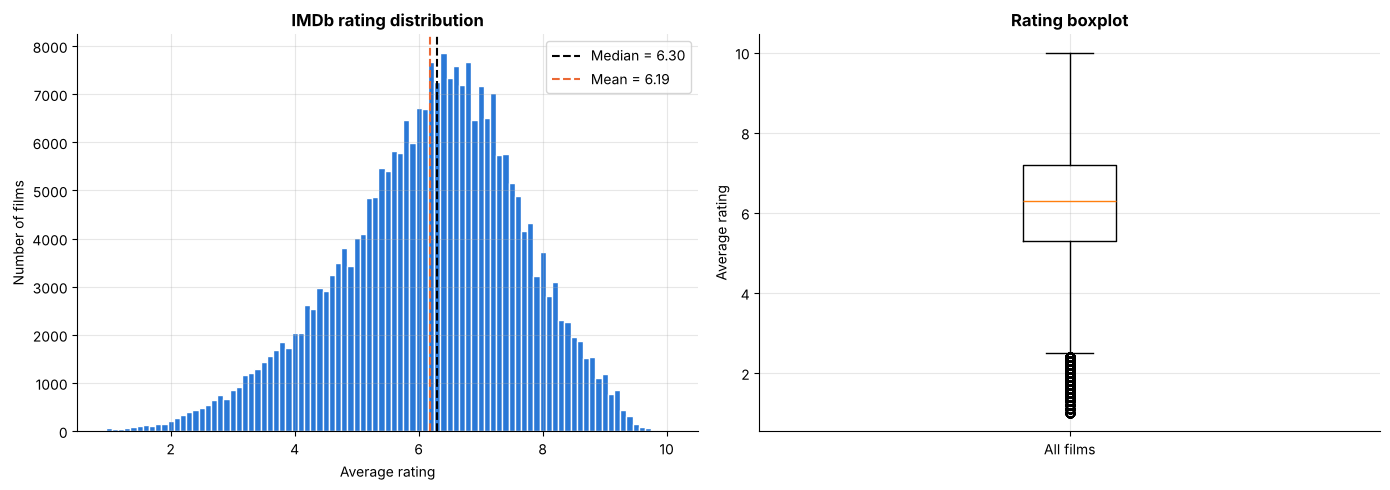

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].hist(df["averageRating"], bins=np.arange(0.95, 10.06, 0.1), color=COLORS["niche"], edgecolor="white")
axes[0].axvline(df["averageRating"].median(), color="black", linestyle="--",
                label=f"Median = {df['averageRating'].median():.2f}")
axes[0].axvline(df["averageRating"].mean(), color=COLORS["mass"], linestyle="--",
                label=f"Mean = {df['averageRating'].mean():.2f}")
axes[0].set(xlabel="Average rating", ylabel="Number of films", title="IMDb rating distribution")
axes[0].legend()

axes[1].boxplot(df["averageRating"])
axes[1].set_xticks([1], ["All films"])
axes[1].set(ylabel="Average rating", title="Rating boxplot")
plt.tight_layout()
save_fig("01_rating_distribution")
plt.show()

**Histogram.** The peak is around 6–7; the left tail goes down to 1–4, the right tail drops sharply near 9–10.
The median (6.30) is slightly to the right of the mean (6.19), confirming the mild negative skew.
Visible spikes at round values (6.0, 7.0, …) come from films with very few votes, whose average can only take a few values.

**Boxplot.** Half of all films are rated between 5.3 and 7.2 (IQR); the median is 6.3. Outliers appear only at
the bottom (below about 2.5). There are none at the top: the upper whisker reaches 10. The rating is the
best-behaved variable in the dataset and needs no transformation.

In [ ]:
print("Rating thresholds:")
thr = pd.DataFrame({"threshold": [7.0, 7.5, 8.0, 8.5, 9.0]})
thr["films"] = [(df["averageRating"] >= t).sum() for t in thr["threshold"]]
thr["share_%"] = (thr["films"] / len(df) * 100).round(2)
display(thr)

print(f"Rating == 10.0: {(df['averageRating'] == 10.0).sum()} films; "
      f"rating == 1.0: {(df['averageRating'] == 1.0).sum()} films")
print("\n10.0-rated films:")
print(df[df["averageRating"] == 10.0].nsmallest(10, "numVotes")
        [["primaryTitle", "startYear", "numVotes", "averageRating"]].to_string(index=False))

Rating thresholds:


,threshold,films,share_%
0,7.0,79989,31.54
1,7.5,47802,18.85
2,8.0,26037,10.27
3,8.5,11843,4.67
4,9.0,3874,1.53


Rating == 10.0: 7 films; rating == 1.0: 75 films

10.0-rated films:
                         primaryTitle  startYear  numVotes  averageRating
                      El Gran Saturán       2023         5           10.0
                       Haunted Scouse       2020         6           10.0
Aiming to the Top - Accra Underground       2025         7           10.0
                         Ami Soumitra       2022         9           10.0
                                Cross       2023        10           10.0
                      The Peace Tapes       1991        10           10.0
                         Mision Delta       2025        57           10.0


**Choice of the "high rating" threshold: 8.0.** It is the 90th percentile and captures the top 10% of films.
7.0 or 7.5 include a third or a fifth of all films, which is too many to call "exceptional". 8.5 or 9.0 leave too few films
for a meaningful analysis of niche cinema.

**Extreme ratings.** Only 7 films have a perfect 10.0, and six of them have 5–10 votes, likely from the crew,
friends or early viewers. A 10.0 with a handful of votes is noise, not a signal. This is why niche films are
selected below with a **minimum of 100 votes**.

## 3.3 Vote count distribution — why a log scale

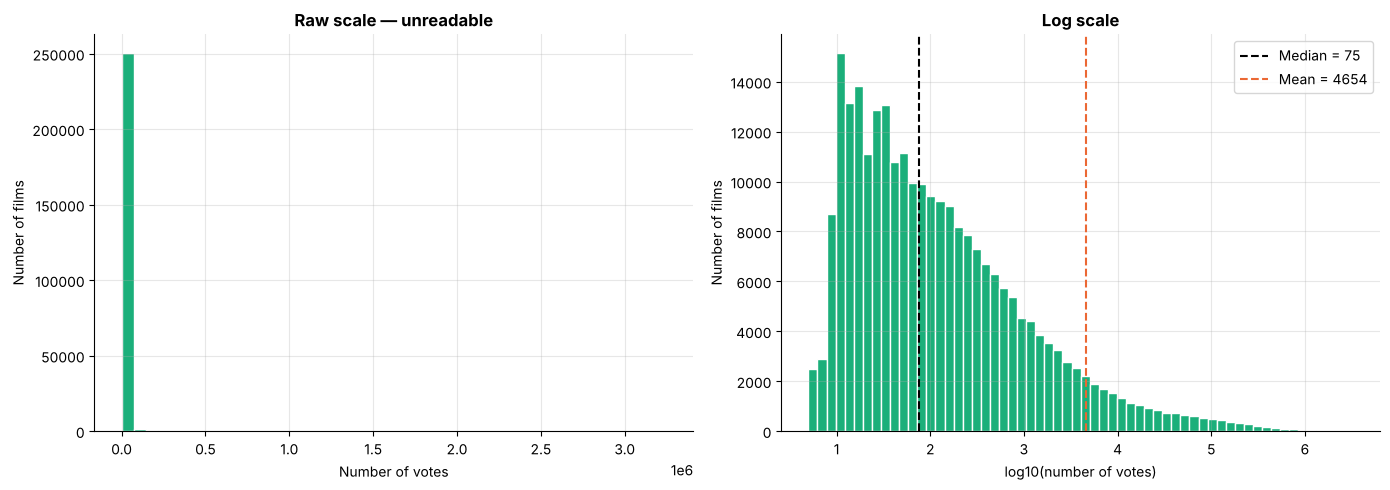

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].hist(df["numVotes"], bins=45, color=COLORS["obscure"], edgecolor="white")
axes[0].set(xlabel="Number of votes", ylabel="Number of films", title="Raw scale — unreadable")

axes[1].hist(np.log10(df["numVotes"]), bins=60, color=COLORS["obscure"], edgecolor="white")
axes[1].axvline(np.log10(df["numVotes"].median()), color="black", linestyle="--",
                label=f"Median = {df['numVotes'].median():.0f}")
axes[1].axvline(np.log10(df["numVotes"].mean()), color=COLORS["mass"], linestyle="--",
                label=f"Mean = {df['numVotes'].mean():.0f}")
axes[1].set(xlabel="log10(number of votes)", ylabel="Number of films", title="Log scale")
axes[1].legend()
plt.tight_layout()
save_fig("02_votes_distribution")
plt.show()

**Raw scale.** Almost all films fall into one bar near zero, while a few blockbusters stretch the axis to
3.2 million votes. **Log scale.** The distribution becomes readable: 80% of films have between 12 and 2,305 votes
(log10 ≈ 1.1–3.4), the median is 75 votes (log10 ≈ 1.9), the mean 4,654 (log10 ≈ 3.7) lies far to the right,
pulled by the tail. It is still right-skewed: the minimum in our data is 5 votes.
**Implication:** votes are always shown on a log scale, and groups are defined by percentiles, not equal-width bins.

## 3.4 How does rating relate to the number of votes?

This is the first part of the research question. We look at the median rating (with the interquartile range)
within vote-count bands, and measure the association with **Spearman's rank correlation**. It is a rank-based measure,
so it is suitable for the skewed `numVotes` and does not assume a linear relationship.

,films,q25,median,q75,mean
vote_band,,,,,
5–19,56213,5.8,6.90,7.8,6.72
20–49,50929,5.5,6.50,7.4,6.40
50–99,32062,5.3,6.30,7.2,6.20
100–499,57683,4.7,5.80,6.6,5.64
500–999,16814,4.8,5.90,6.7,5.69
1K–5K,23530,5.2,6.20,6.9,5.96
5K–10K,5268,5.6,6.30,7.0,6.21
10K–50K,6768,5.7,6.40,7.1,6.33
50K–100K,1751,6.0,6.50,7.1,6.47


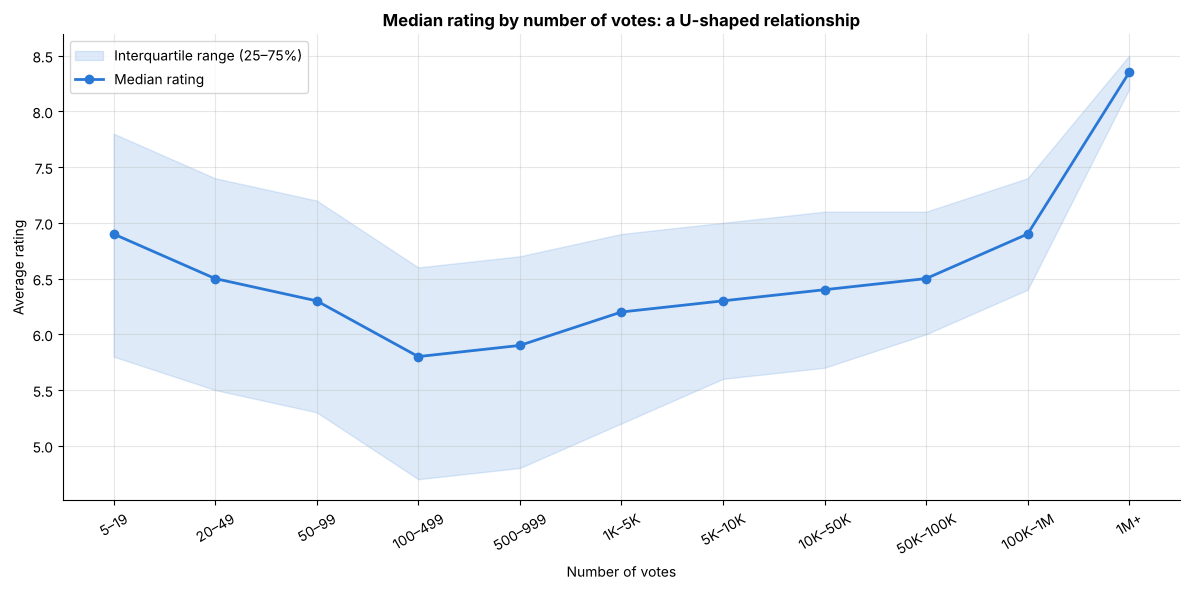

Spearman, all films (n = 253,584):          rho = -0.222, p = 0
Spearman, films with >= 100 votes (n = 114,380): rho = +0.161, p = 0


In [ ]:
VOTE_BANDS = [5, 20, 50, 100, 500, 1_000, 5_000, 10_000, 50_000, 100_000, 1_000_000, np.inf]
BAND_LABELS = ["5–19", "20–49", "50–99", "100–499", "500–999", "1K–5K", "5K–10K",
               "10K–50K", "50K–100K", "100K–1M", "1M+"]
df["vote_band"] = pd.cut(df["numVotes"], VOTE_BANDS, right=False, labels=BAND_LABELS)

band_stats = (df.groupby("vote_band", observed=True)["averageRating"]
                .agg(films="size", q25=lambda s: s.quantile(0.25), median="median",
                     q75=lambda s: s.quantile(0.75), mean="mean"))
display(band_stats.round(2))

fig, ax = plt.subplots(figsize=(12, 6))
x = np.arange(len(band_stats))
ax.fill_between(x, band_stats["q25"], band_stats["q75"], color=COLORS["niche"], alpha=0.15,
                label="Interquartile range (25–75%)")
ax.plot(x, band_stats["median"], color=COLORS["niche"], marker="o", linewidth=2, label="Median rating")
ax.set_xticks(x, band_stats.index, rotation=30)
ax.set(xlabel="Number of votes", ylabel="Average rating",
       title="Median rating by number of votes: a U-shaped relationship")
ax.legend(loc="upper left")
plt.tight_layout()
save_fig("03_rating_by_votes")
plt.show()

MIN_VOTES = 100
rho_all, p_all = stats.spearmanr(df["numVotes"], df["averageRating"])
sub = df[df["numVotes"] >= MIN_VOTES]
rho_100, p_100 = stats.spearmanr(sub["numVotes"], sub["averageRating"])
print(f"Spearman, all films (n = {len(df):,}):          rho = {rho_all:+.3f}, p = {p_all:.2g}")
print(f"Spearman, films with >= {MIN_VOTES} votes (n = {len(sub):,}): rho = {rho_100:+.3f}, p = {p_100:.2g}")

**The relationship is U-shaped, not linear.**

- **Fewer than 100 votes:** the fewer the votes, the *higher* the rating (median 6.9 for 5–19 votes). The
  spread is also widest. With a handful of voters the average is dominated by the film's own circle (crew,
  friends, fans), so the rating is inflated and noisy.
- **100 to about 1,000 votes:** the lowest ratings (median about 5.8). Films that reached a wider but still small
  audience are rated more critically.
- **Above 1,000 votes:** rating rises steadily with popularity and the spread narrows. Films with 1M+ votes have a median of 8.35.
  Popular films are popular partly *because* they are good, and many voters make the average stable.

**Correlation.** Over all films, Spearman's ρ = −0.22, so "more votes, lower rating". Among films with at
least 100 votes the sign **flips**: ρ = +0.16. The sign of the correlation depends on whether the films with very few votes are included: their inflated,
noisy ratings pull the overall coefficient down.
This justifies using the 100-vote floor in the rest of the analysis. With n > 100,000, p-values are essentially zero.
What matters is the size of ρ, and both correlations are **weak**.

## 3.5 Niche films with high ratings

Each film is a point: x = number of votes (log scale), y = rating. We define the **niche high-rated** films
("hidden gems" candidates) as:

- `numVotes ≥ 100`: minimum audience, removes the 5-vote noise from Section 3.2;
- `numVotes ≤ 90th percentile` (2,305): not among the top 10% most-voted films;
- `averageRating ≥ 90th percentile` (8.0): top 10% by rating.

For comparison we use two more groups:

- **mass audience** (`numVotes > 2,305`), the top 10% by votes;
- **ordinary obscure** films: same vote range as niche (100–2,305) but rating < 8.0. This lets us separate the effect of *being highly rated* from the effect of *being little-known*.

Vote threshold (90th percentile): 2,305; rating threshold (90th percentile): 8.0
group
Other (< 100 votes)    139204
Ordinary obscure        86517
Mass audience           25356
Niche high-rated         2507
Name: count, dtype: int64


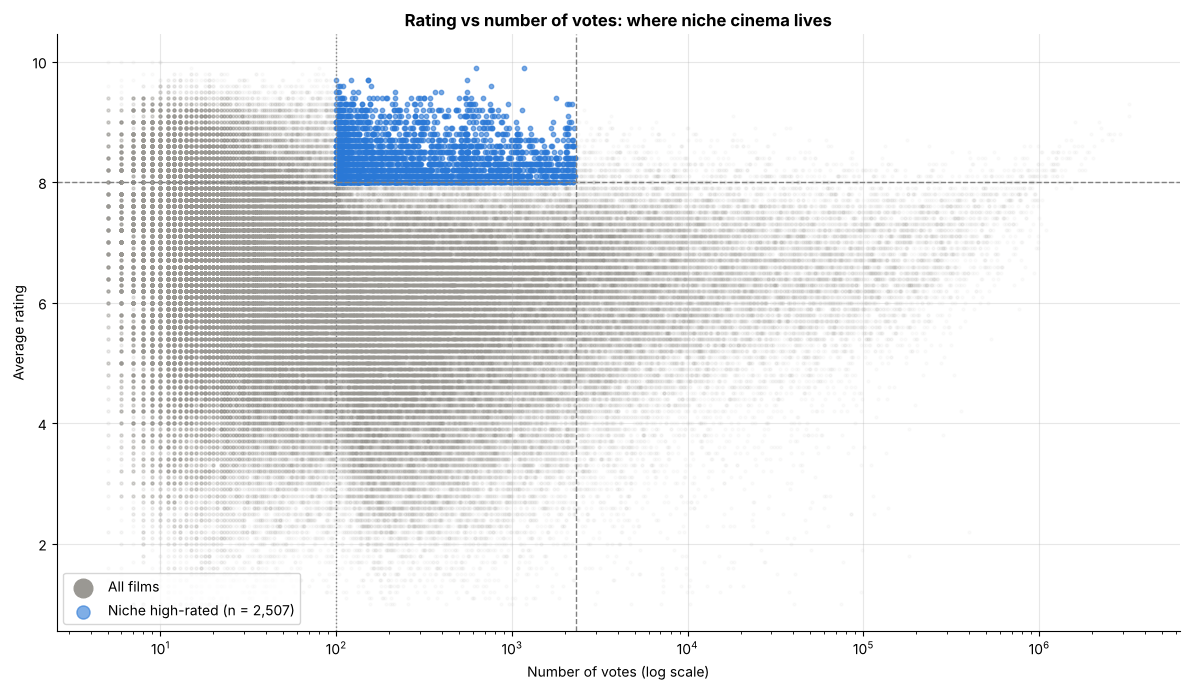

In [ ]:
VOTE_T = df["numVotes"].quantile(0.90)        # 2,305 votes
RATING_T = df["averageRating"].quantile(0.90) # 8.0
print(f"Vote threshold (90th percentile): {VOTE_T:,.0f}; rating threshold (90th percentile): {RATING_T}")

low_vis = (df["numVotes"] >= MIN_VOTES) & (df["numVotes"] <= VOTE_T)
df["group"] = np.select(
    [low_vis & (df["averageRating"] >= RATING_T), low_vis & (df["averageRating"] < RATING_T),
     df["numVotes"] > VOTE_T],
    ["Niche high-rated", "Ordinary obscure", "Mass audience"], default="Other (< 100 votes)")
GROUPS = ["Niche high-rated", "Ordinary obscure", "Mass audience"]
GROUP_COLORS = [COLORS["niche"], COLORS["obscure"], COLORS["mass"]]
print(df["group"].value_counts())

niche = df[df["group"] == "Niche high-rated"]
mass = df[df["group"] == "Mass audience"]
obscure = df[df["group"] == "Ordinary obscure"]

fig, ax = plt.subplots(figsize=(12, 7))
ax.scatter(df["numVotes"], df["averageRating"], s=4, alpha=0.04, color=COLORS["all"])
ax.scatter([], [], s=20, color=COLORS["all"], label="All films")   # visible legend marker
ax.scatter(niche["numVotes"], niche["averageRating"], s=10, alpha=0.6, color=COLORS["niche"],
           label=f"Niche high-rated (n = {len(niche):,})")
ax.axvline(VOTE_T, color="gray", linestyle="--", linewidth=1)
ax.axvline(MIN_VOTES, color="gray", linestyle=":", linewidth=1)
ax.axhline(RATING_T, color="gray", linestyle="--", linewidth=1)
ax.set_xscale("log")
ax.set(xlabel="Number of votes (log scale)", ylabel="Average rating",
       title="Rating vs number of votes: where niche cinema lives")
ax.legend(loc="lower left", markerscale=3)
plt.tight_layout()
save_fig("04_scatter_niche")
plt.show()

**Shape.** The cloud is a funnel: films with few votes cover the whole 1–10 range, while films with many votes
sit in an ever narrower band (see the IQR in Section 3.4). With more voters the average stabilises (law of large numbers). The
top-right corner (very high rating *and* hundreds of thousands of votes) is sparse but not empty: these are the
widely known classics.

**Niche high-rated films:** 2,507 films (about 1% of the dataset) in the top-left box. They form the working set for the
questions about common traits. This is a statistical definition: 2,305 votes is "little-known compared with
blockbusters", not necessarily art-house in the cultural sense.

In [ ]:
top_niche = niche.sort_values(["averageRating", "numVotes", "startYear"], ascending=[False, False, False]).head(20)
display(top_niche[["primaryTitle", "startYear", "genres", "averageRating", "numVotes", "runtimeMinutes"]]
        .reset_index(drop=True))
print(f"Niche candidates: {len(niche):,}; votes {niche['numVotes'].min()}–{niche['numVotes'].max()}; "
      f"perfect 10.0 in the set: {(niche['averageRating'] == 10.0).sum()}")

,primaryTitle,startYear,genres,averageRating,numVotes,runtimeMinutes
0,In Medias Res,2011,Thriller,9.9,1179,90
1,Romantic Weirdos and the Land of Oddz,2007,Drama,9.9,625,145
2,From China with Love,2025,"Crime,Drama,Thriller",9.7,555,<NA>
3,Twenty One Pilots: Cinema Experience Extended Cut,2022,Music,9.7,152,90
4,Illusory Thoughts,1989,"Documentary,Drama,Music",9.7,152,72
5,Fishmans: Otokotachi no Wakare 98.12.28 @ Akas...,2005,Music,9.7,121,<NA>
6,Come pesci nell'acqua,2024,Documentary,9.7,100,120
7,Manmauji,2024,Drama,9.6,760,138
8,Borderline Forever,2021,"Adventure,Comedy,Fantasy",9.6,157,64
9,"I Respond to You, God",1996,Documentary,9.6,109,78


Niche candidates: 2,507; votes 100–2287; perfect 10.0 in the set: 0


**Top niche films.** The shortlist is ranked by rating, then by votes. The top is dominated by documentaries,
concert films and small dramas with 100–1,200 votes and ratings of 9.5–9.9. Even with the 100-vote floor,
ratings this high can still be partly driven by a devoted community, so the list is a shortlist for
inspection, not proof that every title is objectively underrated.

## 3.6 Genres "for the masses" and "for connoisseurs"

Films have up to three genres. Genres are split with `explode()`, so a film counts once in each of its genres.
Genres with fewer than 500 films (Reality-TV, Talk-Show, Game-Show) are excluded as too small.

For every genre we calculate:

- **median votes**: how popular a typical film of the genre is;
- **median rating**;
- **share of mass-audience films**: % of the genre's films in the top 10% by votes;
- **Spearman ρ** between votes and rating, among films with ≥ 100 votes: does audience size go together with higher ratings within the genre?

In [ ]:
MIN_GENRE_N = 500
g = df.assign(genre=df["genres"].str.split(",")).explode("genre")
g["genre"] = g["genre"].str.strip()

rows = []
for genre, s in g.groupby("genre"):
    if len(s) < MIN_GENRE_N:
        continue
    s100 = s[s["numVotes"] >= MIN_VOTES]
    rho, p = stats.spearmanr(s100["numVotes"], s100["averageRating"])
    rows.append({"genre": genre, "films": len(s),
                 "median_votes": s["numVotes"].median(),
                 "median_rating": s["averageRating"].median(),
                 "mass_share_%": (s["numVotes"] > VOTE_T).mean() * 100,
                 "niche_share_%": (s["group"] == "Niche high-rated").mean() * 100,
                 "rho_votes_rating": rho, "p_value": p, "n_100plus": len(s100)})
genre_tab = pd.DataFrame(rows).set_index("genre")

# Bonferroni correction: we run one test per genre
genre_tab["significant"] = genre_tab["p_value"] < 0.05 / len(genre_tab)

# Classify genres relative to the medians of the whole dataset
MED_VOTES, MED_RATING = df["numVotes"].median(), df["averageRating"].median()
def genre_type(r):
    if r["median_votes"] > MED_VOTES and r["median_rating"] < MED_RATING:
        return "For the masses"
    if r["median_votes"] <= MED_VOTES and r["median_rating"] >= MED_RATING:
        return "For connoisseurs"
    if r["median_votes"] > MED_VOTES:
        return "Broad appeal"
    return "Low profile"
genre_tab["type"] = genre_tab.apply(genre_type, axis=1)

display(genre_tab.sort_values("median_votes", ascending=False).round(3))
print(f"Reference lines: median votes = {MED_VOTES:.0f}, median rating = {MED_RATING}")

,films,median_votes,median_rating,mass_share_%,niche_share_%,rho_votes_rating,p_value,n_100plus,significant,type
genre,,,,,,,,,,
Mystery,10578,269.0,5.8,23.294,0.331,0.346,0.000,6781,True,For the masses
Crime,20053,251.0,6.0,23.199,0.598,0.370,0.000,12691,True,For the masses
Adventure,13007,226.0,6.0,23.703,0.653,0.298,0.000,8045,True,For the masses
Sci-Fi,6876,211.0,5.4,19.430,0.291,0.335,0.000,4208,True,For the masses
Thriller,25910,200.0,5.5,16.642,0.648,0.332,0.000,15916,True,For the masses
Romance,25270,187.0,6.1,16.347,0.756,0.280,0.000,15311,True,For the masses
Action,27817,173.0,5.8,19.959,0.697,0.319,0.000,16083,True,For the masses
Fantasy,8439,168.0,5.9,18.272,0.533,0.226,0.000,4972,True,For the masses
Horror,23511,162.0,4.8,14.619,0.183,0.366,0.000,13751,True,For the masses


Reference lines: median votes = 75, median rating = 6.3


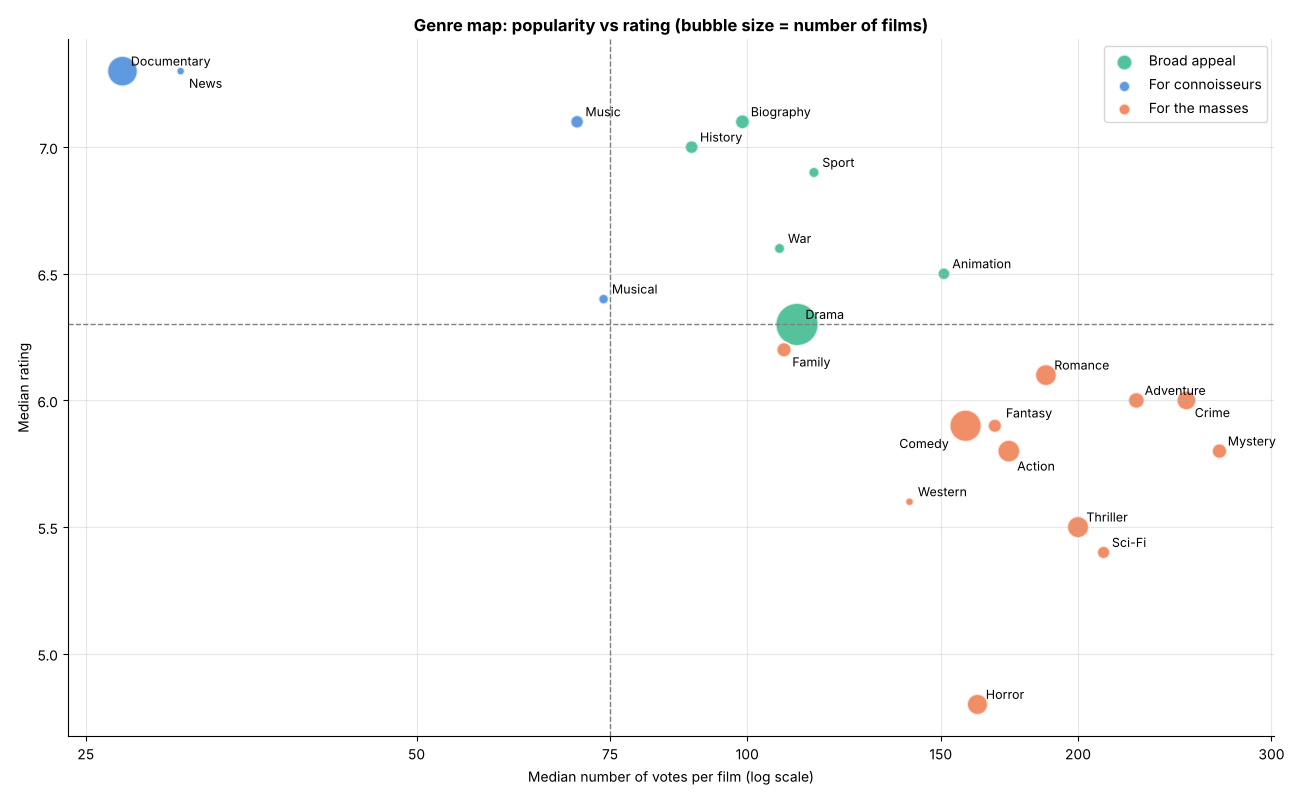

Broad appeal: Animation, Sport, Drama, War, Biography, History
For connoisseurs: Musical, Music, News, Documentary
For the masses: Mystery, Crime, Adventure, Sci-Fi, Thriller, Romance, Action, Fantasy, Horror, Comedy, Western, Family


In [ ]:
TYPE_COLORS = {"For the masses": COLORS["mass"], "For connoisseurs": COLORS["niche"],
               "Broad appeal": COLORS["obscure"], "Low profile": COLORS["all"]}
fig, ax = plt.subplots(figsize=(13, 8))
for t, part in genre_tab.groupby("type"):
    ax.scatter(part["median_votes"], part["median_rating"], s=part["films"] / 120 + 30,
               color=TYPE_COLORS[t], alpha=0.75, edgecolor="white", linewidth=1.5, label=t)
# Label offsets in points (dx, dy); negative dx puts the label to the left of the bubble.
# Fantasy and Comedy almost coincide (168 vs 158 votes, both 5.9), so their labels go to opposite sides.
OFFSETS = {"News": (6, -12), "Crime": (6, -12), "Fantasy": (8, 6), "Comedy": (-12, -16),
           "Action": (6, -14), "Family": (6, -12)}
for name, r in genre_tab.iterrows():
    dx, dy = OFFSETS.get(name, (6, 4))
    ax.annotate(name, (r["median_votes"], r["median_rating"]), xytext=(dx, dy),
                textcoords="offset points", fontsize=9, ha="right" if dx < 0 else "left")
ax.axvline(MED_VOTES, color="gray", linestyle="--", linewidth=1)
ax.axhline(MED_RATING, color="gray", linestyle="--", linewidth=1)
ax.set_xscale("log")
ax.set_xticks([25, 50, 75, 100, 150, 200, 300], ["25", "50", "75", "100", "150", "200", "300"])
ax.minorticks_off()
ax.set(xlabel="Median number of votes per film (log scale)", ylabel="Median rating",
       title="Genre map: popularity vs rating (bubble size = number of films)")
ax.legend(loc="upper right", markerscale=0.5)
plt.tight_layout()
save_fig("05_genre_map")
plt.show()

for t, part in genre_tab.sort_values("median_votes", ascending=False).groupby("type"):
    print(f"{t}: {', '.join(part.index)}")

**Genre map.** Dashed lines are the medians of the whole dataset (75 votes, rating 6.3).

- **For the masses** (bottom right: more votes than typical, lower ratings): Mystery, Crime, Adventure,
  Sci-Fi, Thriller, Romance, Action, Fantasy, Horror, Comedy, Western, Family. These are the genre-cinema
  categories: a typical film gets 108–269 votes, 10–24% of their films reach the top 10% by votes,
  but the median rating is only 4.8–6.2. Horror is the extreme case: 162 median votes and a median rating of only 4.8.
- **For connoisseurs** (top left: few votes, high ratings): Documentary, News, Music, Musical. A typical
  documentary has only 27 votes but a median rating of 7.3; only 2% of documentaries reach the mass-audience group.
  *Musical is a borderline case:* its median is 74 votes (dataset median 75) and its rating 6.4 (dataset median 6.3),
  so a very small change would move it to another type. *News is a small genre:* 668 films, only 165 of them with ≥ 100 votes.
- **Broad appeal** (popular and well rated): Biography, History, Sport, War, Animation, Drama. These are close to the
  centre: slightly above median popularity, with ratings of 6.3–7.1.

Documentaries, music films and biographies are watched by self-selected audiences who are already
interested in the subject, and these audiences rate generously. Genre films reach broad, less selective audiences.

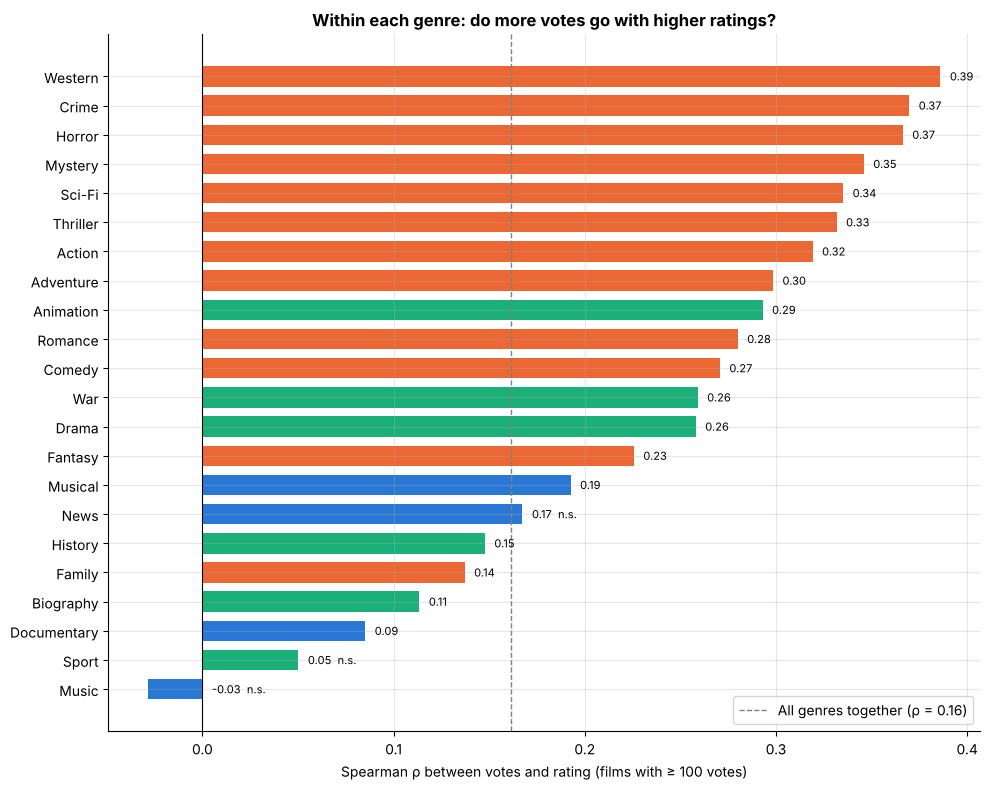

In [ ]:
rho_plot = genre_tab.sort_values("rho_votes_rating")
fig, ax = plt.subplots(figsize=(10, 8))
ax.barh(rho_plot.index, rho_plot["rho_votes_rating"],
        color=[TYPE_COLORS[t] for t in rho_plot["type"]], height=0.7)
ax.axvline(0, color="black", linewidth=0.8)
ax.axvline(rho_100, color="gray", linestyle="--", linewidth=1, label=f"All genres together (ρ = {rho_100:.2f})")
for i, (name, r) in enumerate(rho_plot.iterrows()):
    mark = "" if r["significant"] else "  n.s."
    ax.text(max(r["rho_votes_rating"], 0) + 0.005, i, f"{r['rho_votes_rating']:.2f}{mark}",
            va="center", ha="left", fontsize=8)
ax.set(xlabel="Spearman ρ between votes and rating (films with ≥ 100 votes)",
       title="Within each genre: do more votes go with higher ratings?")
ax.legend(loc="lower right")
plt.tight_layout()
save_fig("06_genre_correlation")
plt.show()

**Relationship between rating and votes inside each genre** (films with ≥ 100 votes; bar colour = genre type
from the map; "n.s." = not significant after the Bonferroni correction).

- In the **mass genres** the link is moderate and positive: ρ ≈ 0.27–0.39 for Western, Crime, Horror, Mystery,
  Sci-Fi, Thriller, Action, Adventure, Romance and Comedy (weaker for Fantasy 0.23 and Family 0.14). Here audience
  size and quality go together: the best thrillers and horror films are also the most watched, and weak ones stay obscure.
- In the **connoisseur and factual genres** the link is weak or absent: Documentary ρ = 0.09, Biography 0.11,
  History 0.15, Musical 0.19. For Music (−0.03), Sport (0.05) and News (0.17) it is not significant after the
  Bonferroni correction (threshold 0.05 / 22 ≈ 0.0023; for News p = 0.03 with only 165 films).
  A documentary with 200 votes is rated about as highly as one with 20,000, so popularity says little about rating.

This is the answer to the first research question: **how rating relates to votes depends on the genre.** In mass genres, popularity is
a reasonable signal of quality. In connoisseur genres it is not, and these genres are where highly rated films
remain little-known.

## 3.7 Common traits of niche films: genre

Is the genre mix of niche high-rated films different from that of mass-audience films? For every genre we
compare the **share of films** that have this genre in the two groups and test the difference with a
**chi-square test** on a 2×2 table (has genre / does not × niche / mass) for the 22 genres with at least 500
films. We run 22 tests, so we use the Bonferroni-corrected significance level 0.05 / 22.

,niche_%,mass_%,chi2,p_value,ratio_niche_to_mass,significant
genre,,,,,,
Documentary,40.606,4.823,3944.837,0.000,8.419,True
News,0.439,0.071,26.249,0.000,6.181,True
Music,9.454,3.281,233.908,0.000,2.881,True
Musical,2.513,1.140,33.397,0.000,2.205,True
Sport,3.710,2.173,23.181,0.000,1.707,True
History,5.983,3.971,22.697,0.000,1.507,True
Biography,8.177,6.365,11.977,0.001,1.285,True
Family,4.627,3.857,3.384,0.066,1.200,False
War,2.074,1.822,0.668,0.414,1.138,False


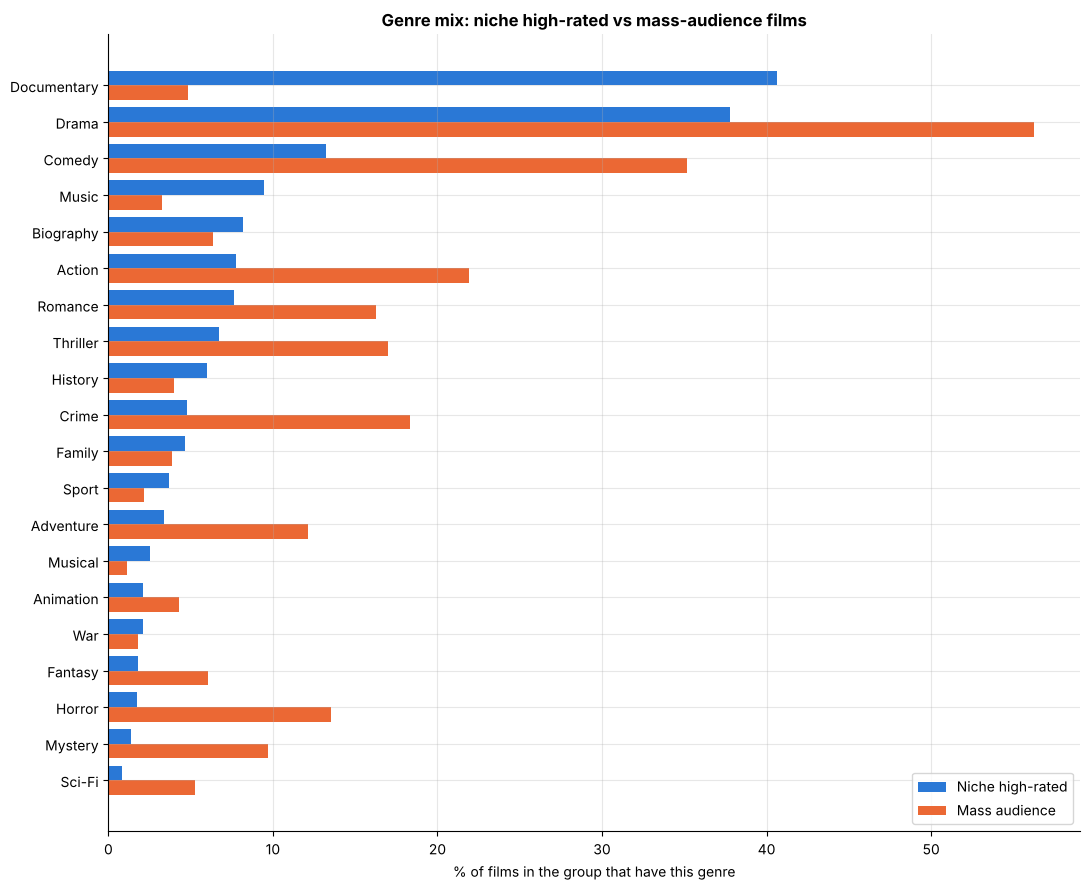

Average number of genres per film:
group
Mass audience       2.44
Niche high-rated    1.67
Name: k, dtype: float64


In [ ]:
pair = df[df["group"].isin(["Niche high-rated", "Mass audience"])]
genre_lists = pair["genres"].str.split(",")
all_genres = list(genre_tab.index)   # the genres with >= 500 films (Section 3.6)
mix = []
for genre in all_genres:
    has = genre_lists.apply(lambda L: genre in L)
    table = pd.crosstab(has, pair["group"])
    if table.shape != (2, 2):
        continue
    chi2, p, dof, expected = stats.chi2_contingency(table)
    mix.append({"genre": genre,
                "niche_%": has[pair["group"] == "Niche high-rated"].mean() * 100,
                "mass_%": has[pair["group"] == "Mass audience"].mean() * 100,
                "chi2": chi2, "p_value": p})
mix = pd.DataFrame(mix).set_index("genre")
mix["ratio_niche_to_mass"] = mix["niche_%"] / mix["mass_%"]
mix["significant"] = mix["p_value"] < 0.05 / len(mix)
display(mix.sort_values("ratio_niche_to_mass", ascending=False).round(3))

show = mix[(mix["niche_%"] >= 1) | (mix["mass_%"] >= 1)].sort_values("niche_%")
fig, ax = plt.subplots(figsize=(11, 9))
y = np.arange(len(show))
ax.barh(y + 0.2, show["niche_%"], height=0.4, color=COLORS["niche"], label="Niche high-rated")
ax.barh(y - 0.2, show["mass_%"], height=0.4, color=COLORS["mass"], label="Mass audience")
ax.set_yticks(y, show.index)
ax.set(xlabel="% of films in the group that have this genre",
       title="Genre mix: niche high-rated vs mass-audience films")
ax.legend(loc="lower right")
plt.tight_layout()
save_fig("07_genre_mix")
plt.show()

n_genres = pair.assign(k=genre_lists.str.len()).groupby("group")["k"].mean()
print("Average number of genres per film:")
print(n_genres.round(2))

**Genre is the strongest common trait of niche films.**

- **Documentary** is in 41% of niche high-rated films but only 5% of mass-audience films (8× more often).
  **Music** is 3× more frequent, **History** 1.5×, **Biography** 1.3×. All differences are significant after
  the Bonferroni correction.
- **Horror, Mystery, Sci-Fi, Crime, Adventure, Fantasy, Action, Comedy and Thriller** are much *less*
  frequent among niche films (from 2.5× for Thriller to 8× for Horror). Drama is common in both groups but more typical of mass films (56% vs 38%).
- Niche films also have **fewer genres per film** (1.7 vs 2.4): they tend to be "pure" documentaries or dramas.
  Mass films more often combine genres (e.g. Action, Adventure, Sci-Fi).

## 3.8 Common traits of niche films: release year and runtime

`runtimeMinutes` and `startYear` are not normally distributed (Section 3.1), so we compare groups with the
non-parametric **Mann–Whitney U test** (H₀: the two distributions are the same; two-sided).
With groups of thousands of films even tiny differences become "significant", so we also report the effect size,
the **rank-biserial correlation** r (from −1 to 1; |r| < 0.1 negligible, about 0.1–0.3 small, about 0.3–0.5 medium).
Positive r = values in the niche group tend to be larger.

In [ ]:
def mann_whitney(a, b):
    a, b = pd.Series(a).dropna().astype(float), pd.Series(b).dropna().astype(float)
    u, p = stats.mannwhitneyu(a, b, alternative="two-sided")
    r = 2 * u / (len(a) * len(b)) - 1          # rank-biserial correlation
    return {"median_niche": a.median(), "median_other": b.median(), "U": u, "p_value": p, "rank_biserial_r": r}

tests = {}
for col in ["startYear", "runtimeMinutes"]:
    for name, other in [("Mass audience", mass), ("Ordinary obscure", obscure)]:
        tests[(col, f"niche vs {name}")] = mann_whitney(niche[col], other[col])
tests = pd.DataFrame(tests).T
display(tests.astype(float).round(4))

summary = (df[df["group"].isin(GROUPS)].groupby("group")
             .agg(films=("tconst", "size"),
                  median_year=("startYear", "median"),
                  median_runtime=("runtimeMinutes", "median"),
                  runtime_q25=("runtimeMinutes", lambda s: s.astype(float).quantile(0.25)),
                  runtime_q75=("runtimeMinutes", lambda s: s.astype(float).quantile(0.75)),
                  runtime_missing_pct=("runtimeMinutes", lambda s: s.isna().mean() * 100))
             .reindex(GROUPS))
display(summary.round(1))

median_niche  median_other            U  p_value  rank_biserial_r
startYear      niche vs Mass audience           2017.0        2012.0   39364513.5    0.000           0.2385
               niche vs Ordinary obscure        2017.0        2013.0  129000722.0    0.000           0.1895
runtimeMinutes niche vs Mass audience            104.0         103.0   28761222.5    0.107          -0.0202
               niche vs Ordinary obscure         104.0          95.0  115760417.5    0.000           0.1732

,films,median_year,median_runtime,runtime_q25,runtime_q75,runtime_missing_pct
group,,,,,,
Niche high-rated,2507,2017.0,104.0,86.0,130.0,7.6
Ordinary obscure,86517,2013.0,95.0,87.0,107.0,1.5
Mass audience,25356,2012.0,103.0,93.0,118.0,0.0


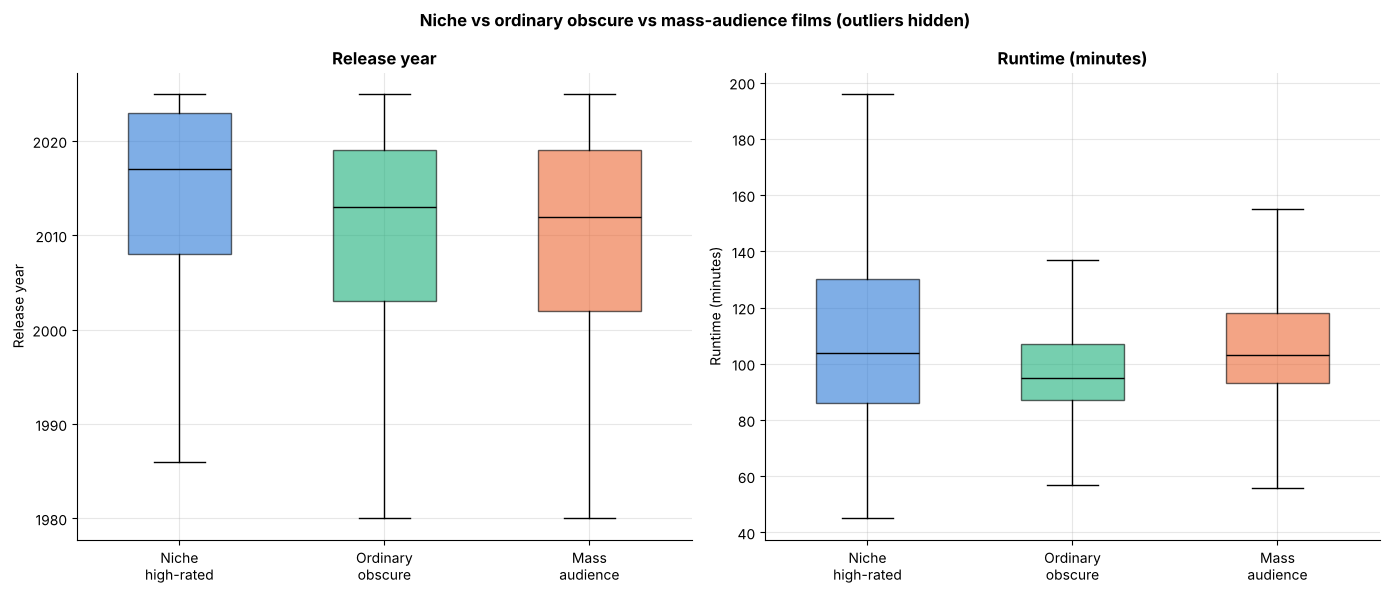

group,Niche high-rated,Ordinary obscure,Mass audience
startYear,,,
1980,7.6,8.8,8.7
1990,8.2,10.2,12.2
2000,12.6,19.5,22.3
2010,32.0,37.0,35.6
2020,39.6,24.4,21.3


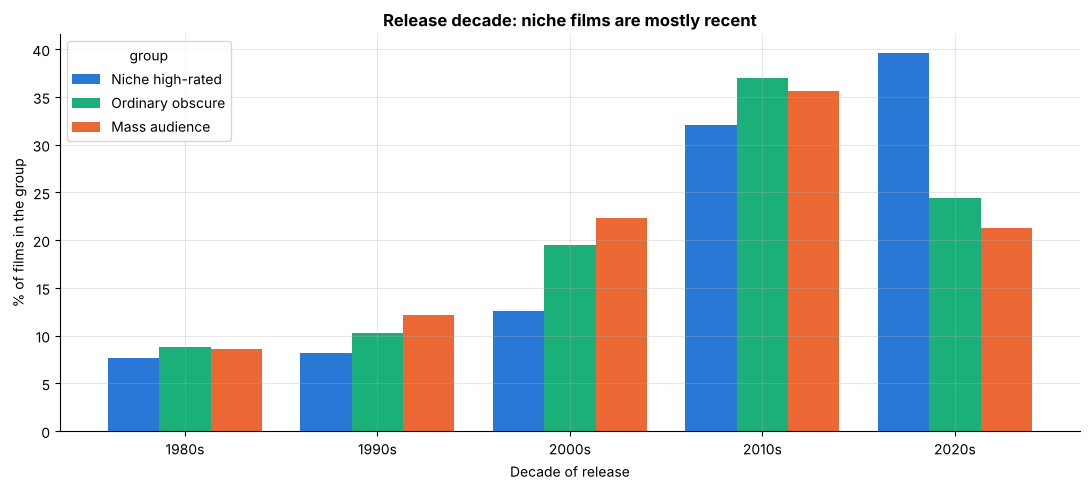

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, col, title in [(axes[0], "startYear", "Release year"), (axes[1], "runtimeMinutes", "Runtime (minutes)")]:
    data = [df.loc[df["group"] == gr, col].dropna().astype(float) for gr in GROUPS]
    bp = ax.boxplot(data, showfliers=False, patch_artist=True, widths=0.5)
    for patch, color in zip(bp["boxes"], GROUP_COLORS):
        patch.set_facecolor(color)
        patch.set_alpha(0.6)
    for median in bp["medians"]:
        median.set_color("black")
    ax.set_xticks([1, 2, 3], ["Niche\nhigh-rated", "Ordinary\nobscure", "Mass\naudience"])
    ax.set(title=title, ylabel=title)
plt.suptitle("Niche vs ordinary obscure vs mass-audience films (outliers hidden)", fontweight="bold")
plt.tight_layout()
save_fig("08_year_runtime_boxplots")
plt.show()

decade = pd.crosstab(df["startYear"] // 10 * 10, df["group"], normalize="columns")[GROUPS] * 100
display(decade.round(1))
ax = decade.plot(kind="bar", color=GROUP_COLORS, figsize=(11, 5), width=0.8)
ax.set(xlabel="Decade of release", ylabel="% of films in the group",
       title="Release decade: niche films are mostly recent")
ax.set_xticklabels([f"{int(d)}s" for d in decade.index], rotation=0)
plt.tight_layout()
save_fig("09_decades")
plt.show()

**Release year: niche films are recent.** Median release year: 2017 for niche high-rated films vs 2012 for
mass-audience films and 2013 for ordinary obscure films (both p < 0.001; small effect, r ≈ 0.24 and 0.19).
40% of niche films come from the 2020s, compared with 21% of mass films. Possible explanations:
(1) new films have not yet collected votes, so good recent films are still "niche" and may become mainstream;
(2) the first voters of a new film are its most enthusiastic fans, and ratings usually fall as the audience grows.
Older films with high ratings had time to become popular, so few of them remain little-known.

**Runtime: no difference from mass films.** Median runtime is 104 minutes for niche films vs 103 for mass films
(p = 0.11, not significant, r ≈ −0.02). However, niche films are **longer and more varied than ordinary obscure
films** (median 104 vs 95 min, p < 0.001, small effect r ≈ 0.17; IQR 86–130 vs 87–107). Long documentaries and
concert films are common among them. A high rating at low visibility goes together with longer, "auteur" running times,
not with short low-budget films. 7.6% of niche films have no runtime on IMDb (vs 0.03% of mass films), which is itself a sign of
less complete metadata for little-known films.

# Stage 4. Key findings, limitations and conclusions

## Key findings

1. **Rating and popularity are related in a U-shape, not in a straight line.** Films with very few votes
   (< 100) have inflated, noisy ratings. Between 100 and about 1,000 votes ratings are lowest. Above that, rating
   grows with popularity (median 8.35 for films with 1M+ votes). The overall Spearman correlation is −0.22, but
   +0.16 for films with ≥ 100 votes. Including or excluding the low-vote noise reverses the sign.
2. **Genres "for the masses":** Horror, Thriller, Sci-Fi, Action, Mystery, Crime, Adventure, Fantasy, Comedy,
   Romance, Family, Western. These genres get more votes than typical but lower ratings. Within them, more votes go with a higher
   rating (ρ up to 0.39; 0.27–0.39 for most of them).
3. **Genres "for connoisseurs":** Documentary, Music, News, Musical. These genres get few votes but high ratings
   (Documentary: median 27 votes, rating 7.3). Within them, rating hardly depends on audience size (ρ ≈ 0–0.2).
   Musical is a borderline case (74 vs 75 median votes), and News is small (668 films).
   Biography, History, Sport, War and Animation combine above-median popularity with high ratings.
4. **Niche high-rated films (2,507 films, about 1%) share clear traits:** they are mostly documentaries, music
   films, histories and biographies (Documentary 8× more often than among mass films); they have fewer genres per
   film; they are recent (median year 2017, 40% from the 2020s). Their runtime is similar to mass films but longer than
   that of ordinary obscure films.

## Limitations

- **IMDb users are not all viewers.** Ratings reflect self-selected, mostly English-speaking, online users; films
  from some countries and older films are under-represented, and the 2010s–2020s dominate the data.
- **"Niche" is a statistical definition** (100–2,305 votes, rating ≥ 8.0, chosen by percentiles), not a cultural one.
  Other thresholds would change the group size, though the 04.10 vs 16.10 comparison shows the results are stable.
- **Few votes means uncertain ratings.** Even with the 100-vote floor, high ratings of small films can be driven by
  fans, crew or campaigns (vote manipulation cannot be detected in this data).
- **Cleaning decisions:** films without a genre (median 16 votes) and adult films were removed; 7.6% of niche films
  lack a runtime.
- **Genre types are defined by medians**, so genres close to the dividing lines (Musical: 74 vs 75 votes) could
  change type with slightly different data; small genres such as News (668 films) give less stable estimates.
- **Multi-genre films** are counted in each of their genres, so genre groups overlap. With very large samples, p-values are always tiny, so
  conclusions are based on effect sizes.
- **Associations, not causes:** the data cannot tell whether a film is popular because it is good or rated highly
  because only fans watch it. Recency is a confounder: newer films have had less time to collect votes.
- **Data version:** IMDb changes daily; the analysis is exactly reproducible on the frozen version from 16.10 and was
  checked against the version from 04.10.

## Conclusions and recommendations

**Conclusion.** The relationship between IMDb rating and popularity depends on the genre. In mass genres (horror,
thriller, action, sci-fi) popularity and rating go together, so the number of votes is a useful signal of quality. In connoisseur genres
(documentary, music, history, biography) highly rated films stay little-known, and popularity says almost nothing
about how good a film is. Niche cinema on IMDb is mainly recent, documentary and music-oriented, "single-genre" cinema.

**Recommendations.**

- *For viewers and recommendation services:* do not use the vote count as a quality filter in documentary, music,
  biography and history films. Use a minimum-vote floor (about 100 votes) instead of ranking by votes, and show the vote count next to the rating.
- *For streaming platforms and festivals:* documentaries and music films are the richest source of under-exposed
  high-quality titles, so curated collections of these genres are a natural way to surface them.
- *For distributors of genre films (horror, thriller, action):* the audience is large but critical. Ratings grow with
  audience size, so quality pays off in visibility.
- *For analysts:* never rank films by raw average rating without a vote threshold, and check whether a pattern
  holds within segments (genres, vote bands) before trusting an aggregate number.
- *Further research:* add country/language data (`title.akas`) and crew data (`title.principals`) to see whether
  niche films come from specific countries or directors; track the same films over time to test whether recent niche films become mainstream.

In [ ]:
print("Figures saved for the report:")
for f in sorted(FIG_DIR.glob("*.png")):
    print(" -", f)
print("\nNotebook finished without errors.")

Figures saved for the report:
 - figures/01_rating_distribution.png
 - figures/02_votes_distribution.png
 - figures/03_rating_by_votes.png
 - figures/04_scatter_niche.png
 - figures/05_genre_map.png
 - figures/06_genre_correlation.png
 - figures/07_genre_mix.png
 - figures/08_year_runtime_boxplots.png
 - figures/09_decades.png

Notebook finished without errors.
